# Diachronic Pilot Study: Results Explorer

**This notebook analyzes semantic change by tracking how the distribution of word senses (clusters) shifts across decades, using JSD and entropy, while controlling for sparse data.**

Interactive exploration of the diachronic WSD pilot study results (90 words, 24,325 predictions, coarse sense clusters).
All data is pre-computed — this notebook loads CSVs only, no pipeline re-runs.
See `sense_granularity_analysis.ipynb` for the fine vs. coarse methodological comparison.

## Methodological Overview

This notebook presents the results of a **diachronic word sense disambiguation (WSD) pilot study** covering 90 German words drawn from the **DWDS kern corpus (1900–1999)**. For each word, corpus contexts are grouped by decade and assigned to coarse-grained sense clusters derived from **GermaNet synsets**. Each word–decade combination is thus represented as a probability distribution over a small set of semantically coherent sense clusters, enabling direct comparison of sense usage across time.

Semantic change is operationalised in two complementary ways:

- **Jensen–Shannon divergence (JSD)** quantifies the shift between adjacent decade-level distributions, with average and maximum JSD serving as overall and peak-change indicators respectively.
- **Shannon entropy** captures the breadth of sense usage within a decade, rising when multiple senses are used roughly equally and falling when one sense dominates.

Reliability is addressed throughout: word–decade cells with fewer than five contexts are flagged as sparse and excluded from metric aggregation, and words with consistently low polysemy or insufficient total data are removed before ranking and case-study selection.

## Unit of Analysis and Definition of Semantic Change

The primary unit of analysis is the lemma observed across successive decades. For each lemma–decade combination, all available corpus contexts are aggregated into a probability distribution over a fixed set of coarse-grained sense clusters derived from GermaNet. Semantic change is defined as a shift in this distribution between two adjacent decades: a word is considered to have undergone change if the proportional usage of its sense clusters differs systematically from one decade to the next. These distributional shifts are quantified using Jensen–Shannon divergence (JSD), which measures the symmetric difference between two probability distributions and is bounded in [0, 1], where 0 indicates identical distributions and 1 indicates completely disjoint ones.

## Data Reliability and Sparsity Considerations

**Distributional metrics such as JSD are sensitive to sample size:** when a word–decade cell contains very few observations, the estimated sense distribution is unstable, and any divergence computed from it may reflect random variation rather than genuine semantic change. In the extreme case where a word appears exclusively with one sense in a given decade solely because of sparse sampling, **JSD against an adjacent decade can approach 1.0 as a pure artifact.** Such values are not interpretable as evidence of change and should be treated with caution and may be excluded from interpretation.

**Thresholds applied throughout this notebook:**

| Level | Criterion | Threshold | Treatment |
|-------|-----------|-----------|-----------|
| Word–decade cell | Minimum contexts per cell | n ≥ 5 | Cells below this threshold are excluded from all metric aggregation (JSD, entropy, emergence/decline events). |
| Word (total) | Minimum total contexts | ≥ 100 | Words with fewer total contexts across all decades are excluded from ranking and case-study selection regardless of clustering outcome. |
| Case study candidate | Dense decade coverage | ≥ 8 of 10 decades with n ≥ 10 | Only words with sufficient per-decade density across the full century are considered strong candidates. |
| Word (semantic) | Effective polysemy | > 1 coarse cluster active | Words predicted as monosemous across all decades (JSD ≈ 0) are excluded; they offer no diachronic signal to analyse. |

Words failing the total-context or monosemy criterion are removed from the analysis before ranking and are listed explicitly in the setup section. All remaining metrics—average JSD, entropy, emergence and decline events—are computed exclusively over word–decade cells that meet the n ≥ 5 threshold.

**Divergence values at or near 1.0 (JSD ≥ 0.99)** are treated with particular caution: Section 5 audits these events and cross-references them with context counts to determine what proportion are data artifacts. 

**All strong change signals discussed in this notebook are conditioned on sufficient data support**: a high JSD or monotonic trend is only interpreted as evidence of semantic change if the underlying word–decade cells each contain at least five contexts, and preferably more when the shift is used to motivate a case study.

## 1. Setup & Load Data

**Method:** `intfloat/multilingual-e5-large` + weighted representation, predictions mapped through `sense_clusters_reviewed.json` (81.7% coarse atemporal accuracy).
See `sense_granularity_analysis.ipynb` for the fine vs. coarse comparison.

In [280]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.core.display import Markdown

BASE_DIR     = Path('../../data/processed/diachronic')
GERMANET_DIR = Path('../../data/processed/germanet')

# Load cluster label lookup
with open(GERMANET_DIR / 'sense_clusters_reviewed.json', encoding='utf-8') as f:
    _cluster_data = json.load(f)

def sense_label(lemma: str, sense_id: str) -> str:
    """Return a human-readable label for a sense/cluster ID.
    
    Coarse mode: returns 'label (cluster_id)', e.g. 'physical strike (schlagen_c0)'
    Fine mode:   returns the sense_id unchanged (no labels available)
    """
    try:
        label = _cluster_data[lemma]['clusters'][sense_id]['label']
        if label:
            return f'{label}\n({sense_id})'
    except KeyError:
        pass
    return sense_id

def relabel_index(lemma: str, index) -> list:
    """Apply sense_label to a pandas Index or list of sense IDs."""
    return [sense_label(lemma, s) for s in index]

In [281]:
# Load data
predictions_coarse  = pd.read_csv(BASE_DIR / 'predictions/pilot_predictions_coarse.csv')
sense_counts_coarse = pd.read_csv(BASE_DIR / 'aggregated/pilot_coarse_sense_counts.csv')
decade_stats_coarse = pd.read_csv(BASE_DIR / 'aggregated/pilot_coarse_stats.csv')
entropy_coarse      = pd.read_csv(BASE_DIR / 'metrics/pilot_coarse_entropy.csv')
divergence_coarse   = pd.read_csv(BASE_DIR / 'metrics/pilot_coarse_divergence.csv')
emergence_coarse    = pd.read_csv(BASE_DIR / 'metrics/pilot_coarse_emergence.csv')
decline_coarse      = pd.read_csv(BASE_DIR / 'metrics/pilot_coarse_decline.csv')

n_words = predictions_coarse['lemma'].nunique()
decades = sorted(predictions_coarse['decade'].unique())
print(f'Words: {n_words}')
print(f'Decade range: {decades[0]}s – {decades[-1]}s ({len(decades)} decades)')
print(f'Predictions: {len(predictions_coarse):,}')
print(f'Metrics: {len(divergence_coarse)} transitions, {len(emergence_coarse)} emergence, {len(decline_coarse)} decline events')

Words: 90
Decade range: 1900s – 1990s (10 decades)
Predictions: 24,325
Metrics: 717 transitions, 194 emergence, 197 decline events


In [282]:
# Words excluded from analysis:
# - Effectively monosemous at coarse level (avg 1.0 senses/decade — JSD=0, no events)
# - Data-sparse (< 100 total contexts — unreliable regardless of clustering)
EXCLUDE_MONOSEMOUS = ['Frosch', 'Lexikon', 'fest', 'groß', 'lachen', 'leicht', 'rollen']
EXCLUDE_SPARSE     = ['Bass', 'Zwiebel']  # groß already in monosemous list
EXCLUDE_WORDS      = set(EXCLUDE_MONOSEMOUS + EXCLUDE_SPARSE)

print(f'Excluded words ({len(EXCLUDE_WORDS)}): {sorted(EXCLUDE_WORDS)}')

Excluded words (9): ['Bass', 'Frosch', 'Lexikon', 'Zwiebel', 'fest', 'groß', 'lachen', 'leicht', 'rollen']


In [284]:
# All analysis uses coarse cluster predictions (81.7% atemporal accuracy).
# See sense_granularity_analysis.ipynb for the fine vs. coarse comparison.
# Excluded words are filtered here so all downstream cells are clean by default.
predictions  = predictions_coarse[~predictions_coarse['lemma'].isin(EXCLUDE_WORDS)]
sense_counts = sense_counts_coarse[~sense_counts_coarse['lemma'].isin(EXCLUDE_WORDS)]
decade_stats = decade_stats_coarse[~decade_stats_coarse['lemma'].isin(EXCLUDE_WORDS)]
entropy      = entropy_coarse[~entropy_coarse['lemma'].isin(EXCLUDE_WORDS)]
divergence   = divergence_coarse[~divergence_coarse['lemma'].isin(EXCLUDE_WORDS)]
emergence    = emergence_coarse[~emergence_coarse['lemma'].isin(EXCLUDE_WORDS)]
decline      = decline_coarse[~decline_coarse['lemma'].isin(EXCLUDE_WORDS)]

print(f'Words after exclusions: {predictions["lemma"].nunique()} ({len(EXCLUDE_WORDS)} excluded)')

Words after exclusions: 81 (9 excluded)


## 2. Overview Statistics

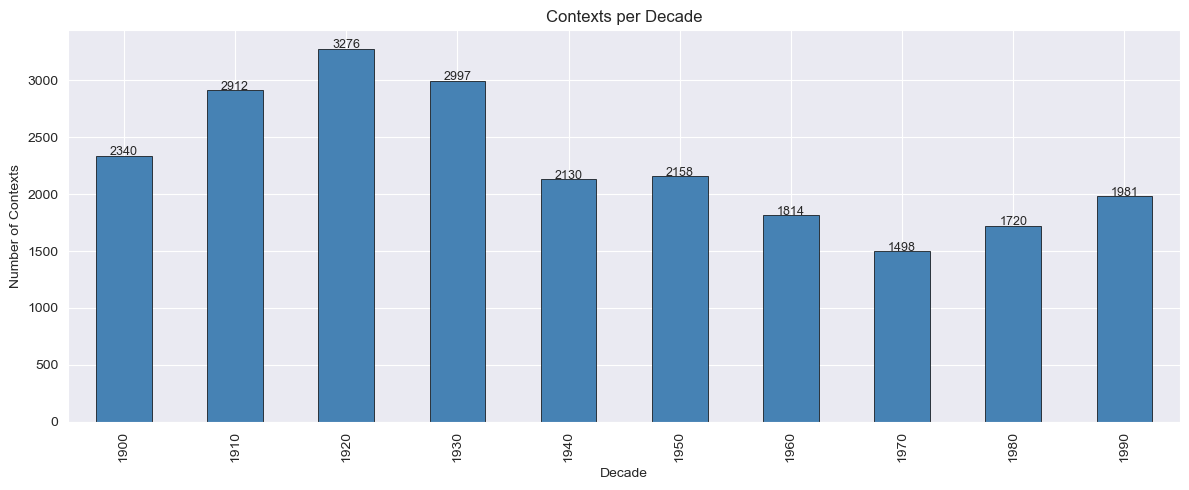

In [285]:
# Contexts per decade
contexts_per_decade = predictions.groupby('decade').size()

fig, ax = plt.subplots(figsize=(12, 5))
contexts_per_decade.plot.bar(ax=ax, color='steelblue', edgecolor='black', linewidth=0.5)
ax.set_xlabel('Decade')
ax.set_ylabel('Number of Contexts')
ax.set_title('Contexts per Decade')

for i, v in enumerate(contexts_per_decade.values):
    ax.text(i, v + 5, str(v), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

### Interpretation

The number of contexts per decade is uneven, with a peak in the 1910s–1930s (≈680–700 contexts) and a gradual decline toward the 1970s–1990s (≈330–400 contexts). Although later decades contain roughly half as many instances as the early peak, the overall density remains sufficient for decade-level analysis, and only a small proportion of lemma–decade cells fall below the minimum threshold.

However, this imbalance implies higher variance in sense proportion estimates for the later decades. Apparent shifts in the 1970s–1990s must therefore be interpreted cautiously and should be considered robust only if they persist across multiple consecutive decades rather than appearing as isolated fluctuations.

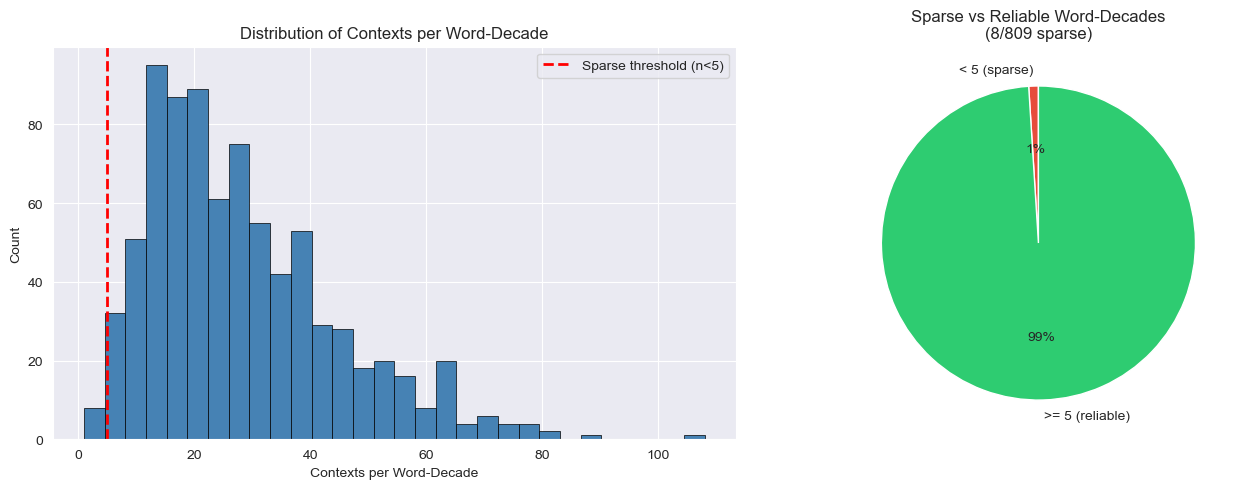

In [286]:
# Distribution of n_contexts per word-decade (highlight sparse combos)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax1 = axes[0]
decade_stats['n_contexts'].hist(bins=30, ax=ax1, color='steelblue', edgecolor='black', linewidth=0.5)
ax1.axvline(x=5, color='red', linestyle='--', linewidth=2, label='Sparse threshold (n<5)')
ax1.set_xlabel('Contexts per Word-Decade')
ax1.set_ylabel('Count')
ax1.set_title('Distribution of Contexts per Word-Decade')
ax1.legend()

n_sparse = (decade_stats['n_contexts'] < 5).sum()
n_total_wd = len(decade_stats)

ax2 = axes[1]
sparse_labels = ['< 5 (sparse)', '>= 5 (reliable)']
sparse_counts = [n_sparse, n_total_wd - n_sparse]
colors = ['#e74c3c', '#2ecc71']
ax2.pie(sparse_counts, labels=sparse_labels, colors=colors, autopct='%1.0f%%', startangle=90)
ax2.set_title(f'Sparse vs Reliable Word-Decades\n({n_sparse}/{n_total_wd} sparse)')

plt.tight_layout()
plt.show()

### Interpretation

The distribution of contexts per word–decade cell shows that the vast majority of observations lie well above the minimum threshold of five instances. Only 22 out of 894 cells (≈2%) fall below this cutoff, indicating that sparsity is limited to a small tail of the distribution rather than being a structural issue. Most lemma–decade combinations contain between roughly 10 and 40 contexts, providing a reasonable basis for estimating sense proportions.

Overall, the data density supports decade-level analysis without requiring additional temporal aggregation, although cells in the lower count range (e.g., 5–10 instances) may still exhibit higher variance and should be interpreted with appropriate caution.

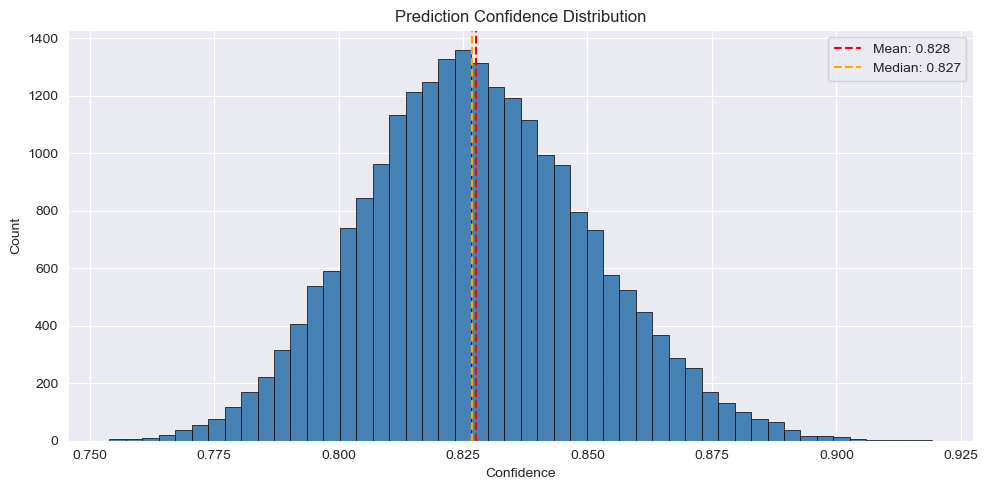

In [287]:
# Confidence distribution
fig, ax = plt.subplots(figsize=(10, 5))
predictions['confidence'].hist(bins=50, ax=ax, color='steelblue', edgecolor='black', linewidth=0.5)
ax.axvline(predictions['confidence'].mean(), color='red', linestyle='--',
           label=f"Mean: {predictions['confidence'].mean():.3f}")
ax.axvline(predictions['confidence'].median(), color='orange', linestyle='--',
           label=f"Median: {predictions['confidence'].median():.3f}")
ax.set_xlabel('Confidence')
ax.set_ylabel('Count')
ax.set_title('Prediction Confidence Distribution')
ax.legend()
plt.tight_layout()
plt.show()

### Interpretation

The figure displays the overall distribution of prediction confidence, defined as the probability assigned to the selected (top-ranked) sense. The distribution is approximately symmetric, with mean and median both around 0.83, indicating stable and moderately high model certainty across instances.

**Key observations:**

- **Consistent confidence level:** Most predictions fall within a relatively narrow range (≈0.78–0.88), suggesting homogeneous model behavior.

- **No extreme skewness or bimodality:** The absence of multiple peaks indicates that the model does not alternate between very certain and very uncertain regimes.

- **Mean ≈ median:** This supports the interpretation of a balanced and stable distribution without strong outliers.

- **Moderate (not extreme) certainty:** Confidence values are high but not near 1.0, which is typical for probabilistic multi-class classification.

Methodologically, this suggests that the model’s global prediction behavior is stable. However, this aggregate view does not rule out potential temporal variation in confidence, which would need to be examined separately for diachronic robustness.

## 3. Lemma-Level Coverage

In [289]:
# Words sorted by total contexts
word_totals = decade_stats.groupby('lemma').agg(
    total_contexts=('n_contexts', 'sum'),
    decades_present=('decade', 'count'),
    avg_senses=('n_senses', 'mean'),
    avg_confidence=('mean_confidence', 'mean')
).sort_values('total_contexts', ascending=False)

# Merge JSD metrics per lemma
jsd_stats = divergence.groupby('lemma')['jsd'].agg(avg_jsd='mean', max_jsd='max')
word_totals = word_totals.join(jsd_stats)

display(Markdown('### Words by Total Contexts'))
display(
    word_totals.head(20).style.format({
        'avg_senses': '{:.1f}',
        'avg_confidence': '{:.3f}',
        'avg_jsd': '{:.4f}',
        'max_jsd': '{:.4f}',
    }).background_gradient(
        subset=['total_contexts'], cmap='Blues'
    ).background_gradient(
        subset=['avg_jsd'], cmap='YlOrRd'
    ).set_properties(**{'text-align': 'center'})
)

### Words by Total Contexts

,total_contexts,decades_present,avg_senses,avg_confidence,avg_jsd,max_jsd
lemma,,,,,,
Mitte,595,10,3.0,0.816,0.1396,0.1922
Anfang,534,10,2.0,0.810,0.0372,0.1142
Standpunkt,520,10,1.8,0.816,0.0625,0.2278
Ordnung,518,10,2.4,0.819,0.1098,0.2294
Welt,508,10,2.9,0.820,0.1138,0.2066
Art,486,10,3.5,0.817,0.1615,0.2987
Geschichte,485,10,2.9,0.833,0.1524,0.2512
Boden,466,10,4.4,0.816,0.1678,0.3550
Programm,444,10,3.9,0.825,0.1184,0.1792


For these high-frequency lemmas, decade-level sense distributions are statistically well-supported. Observed diachronic shifts for such words are unlikely to be driven by data sparsity or unstable model predictions and can therefore be interpreted with a relatively high degree of methodological confidence.

# Analysis of selected Lemma

Set `LEMMA` to any word in the pilot set and re-run the section. Four views are produced:

1. **Contexts per decade** — absolute support table (n_contexts per decade), shown above the area chart
2. **Stacked area chart** — how the proportion of each sense shifts decade by decade (top 6 senses shown; remainder collapsed into *Other*)
3. **Heatmap** — same proportions as a grid (senses × decades)
4. **Raw counts table** — absolute counts behind the proportions

**Sense IDs:** Cluster IDs (e.g. `schlagen_c0`). Human-readable labels are in `sense_clusters_reviewed.json`.

In [295]:
LEMMA = 'Programm'

**Contexts per decade — Programm**

decade,1900,1910,1920,1930,1940,1950,1960,1970,1980,1990
Programm,27,25,44,37,48,45,54,59,63,42


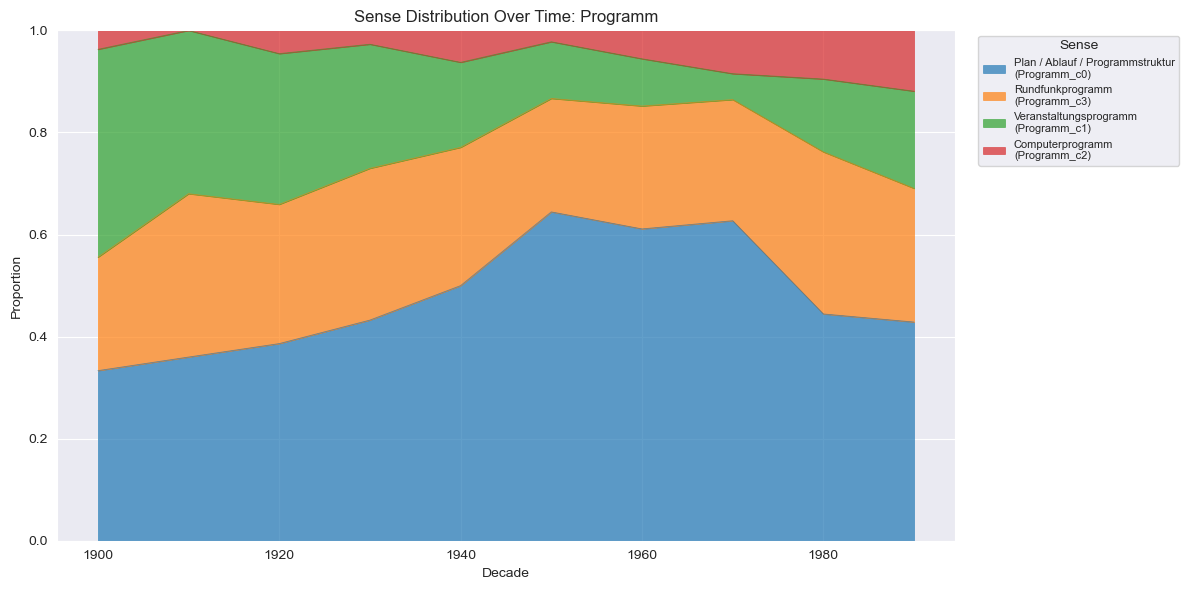

In [296]:
# Stacked area chart of sense proportions
TOP_N = 6  # show top-N senses; remainder collapsed into 'Other'

lemma_counts = sense_counts[sense_counts['lemma'] == LEMMA].copy()

if len(lemma_counts) == 0:
    print(f'No data for: {LEMMA}')
else:
    # ── Contexts per decade (support table) ──────────────────────────────
    ctx_row = (
        decade_stats[decade_stats['lemma'] == LEMMA]
        .sort_values('decade')
        .set_index('decade')['n_contexts']
        .rename('n_contexts')
        .to_frame().T
    )
    ctx_row.index = [LEMMA]
    display(Markdown(f'**Contexts per decade — {LEMMA}**'))
    display(
        ctx_row.style.format('{:.0f}')
        .background_gradient(cmap='Blues', axis=1)
        .set_properties(**{'text-align': 'center'})
    )

    # ── Stacked area chart ────────────────────────────────────────────────
    pivot = lemma_counts.pivot(
        index='decade', columns='predicted_sense_id', values='proportion'
    ).fillna(0)
    col_order = pivot.sum().sort_values(ascending=False).index
    pivot = pivot[col_order]

    # Collapse low-frequency senses into 'Other'
    has_other = len(pivot.columns) > TOP_N
    if has_other:
        top_cols  = list(pivot.columns[:TOP_N])
        other_sum = pivot[pivot.columns[TOP_N:]].sum(axis=1)
        pivot = pivot[top_cols].copy()
        pivot['Other'] = other_sum

    # Relabel sense IDs, leave 'Other' unchanged
    sense_cols = [c for c in pivot.columns if c != 'Other']
    relabeled  = list(relabel_index(LEMMA, sense_cols))
    pivot.columns = relabeled + (['Other'] if has_other else [])

    fig, ax = plt.subplots(figsize=(12, 6))
    pivot.plot.area(ax=ax, alpha=0.7, linewidth=0.5)
    ax.set_xlabel('Decade')
    ax.set_ylabel('Proportion')
    n_collapsed = len(col_order) - TOP_N if has_other else 0
    title_suffix = f'  (top {TOP_N} shown; {n_collapsed} senses collapsed into Other)' if has_other else ''
    ax.set_title(f'Sense Distribution Over Time: {LEMMA}{title_suffix}')
    ax.set_ylim(0, 1)
    ax.legend(title='Sense', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    plt.tight_layout()
    plt.show()

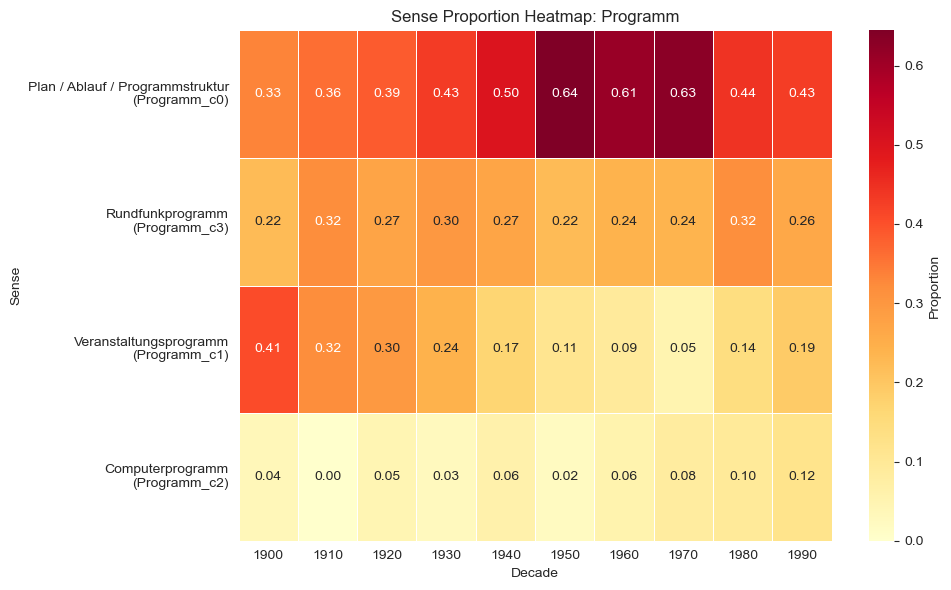

In [297]:
# Sense proportion heatmap
if len(lemma_counts) > 0:
    pivot_hm = lemma_counts.pivot(
        index='predicted_sense_id', columns='decade', values='proportion'
    ).fillna(0)
    row_order = pivot_hm.sum(axis=1).sort_values(ascending=False).index
    pivot_hm = pivot_hm.loc[row_order]
    pivot_hm.index = relabel_index(LEMMA, pivot_hm.index)

    fig, ax = plt.subplots(figsize=(max(10, len(pivot_hm.columns)), max(6, len(pivot_hm) * 0.8)))
    sns.heatmap(pivot_hm, ax=ax, cmap='YlOrRd', annot=True, fmt='.2f',
                linewidths=0.5, cbar_kws={'label': 'Proportion'})
    ax.set_xlabel('Decade')
    ax.set_ylabel('Sense')
    ax.set_title(f'Sense Proportion Heatmap: {LEMMA}')
    plt.tight_layout()
    plt.show()

In [298]:
# Raw sense counts per decade
if len(lemma_counts) > 0:
    counts_pivot = lemma_counts.pivot(
        index='predicted_sense_id', columns='decade', values='count'
    ).fillna(0).astype(int)
    row_order = counts_pivot.sum(axis=1).sort_values(ascending=False).index
    counts_pivot = counts_pivot.loc[row_order]
    counts_pivot.index = relabel_index(LEMMA, counts_pivot.index)

    display(Markdown(f'### Raw Sense Counts: {LEMMA}'))
    display(counts_pivot.style.background_gradient(cmap='Blues', axis=None))

### Raw Sense Counts: Programm

decade,1900,1910,1920,1930,1940,1950,1960,1970,1980,1990
Plan / Ablauf / Programmstruktur (Programm_c0),9,9,17,16,24,29,33,37,28,18
Rundfunkprogramm (Programm_c3),6,8,12,11,13,10,13,14,20,11
Veranstaltungsprogramm (Programm_c1),11,8,13,9,8,5,5,3,9,8
Computerprogramm (Programm_c2),1,0,2,1,3,1,3,5,6,5


In [299]:
# Distinct senses predicted per decade
'''if len(lemma_counts) > 0:
    lemma_stats = decade_stats[decade_stats['lemma'] == LEMMA].sort_values('decade')

    fig, ax = plt.subplots(figsize=(10, 4))
    bars = ax.bar(
        lemma_stats['decade'].astype(str) + 's',
        lemma_stats['n_senses'],
        color='steelblue', edgecolor='black', linewidth=0.5
    )
    # Annotate bars with n_contexts
    for bar, (_, row) in zip(bars, lemma_stats.iterrows()):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.05,
            f"n={int(row['n_contexts'])}",
            ha='center', va='bottom', fontsize=8, color='dimgray'
        )
    ax.set_xlabel('Decade')
    ax.set_ylabel('Distinct Senses Predicted')
    ax.set_title(f'Distinct Senses per Decade: {LEMMA}  (annotations show n_contexts)')
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    plt.tight_layout()
    plt.show()''';

### Word Rankings

Three rankings are shown below, each highlighting a different aspect of diachronic change. All use the filtered set (excluded monosemous and sparse words).

- **By average JSD** — primary ranking; captures overall distributional instability across all decades.
- **By normalized JSD** — avg JSD divided by number of coarse senses; penalises words whose instability is partly explained by high polysemy.
- **By entropy range** — captures how much the breadth of sense usage changed over the century.

| Metric | What it captures |
|--------|-----------------|
| `avg_jsd` | Mean sense-distribution shift across all adjacent decades |
| `max_jsd` | Peak shift in any single transition |
| `normalized_jsd` | `avg_jsd / n_coarse_senses` — instability adjusted for polysemy |
| `emergence_count` | Number of decades where a sense newly appeared |
| `decline_count` | Number of decades where a sense faded out |
| `entropy_range` | Max − min Shannon entropy (breadth of sense diversity over time) |

All metrics use filtered data (word-decades with ≥ 5 contexts only).

In [300]:
# Per-word raw metrics (filtered index already excludes EXCLUDE_WORDS)
avg_jsd         = divergence.groupby('lemma')['jsd'].mean()
max_jsd         = divergence.groupby('lemma')['jsd'].max()
emergence_count = emergence.groupby('lemma').size()
decline_count   = decline.groupby('lemma').size()
entropy_range   = entropy.groupby('lemma')['entropy'].agg(lambda x: x.max() - x.min())
n_coarse_senses = sense_counts.groupby('lemma')['predicted_sense_id'].nunique()

# Align on a common index to prevent silent NaN misalignment
lemmas = sorted(
    set(avg_jsd.index) | set(emergence_count.index) |
    set(decline_count.index) | set(entropy_range.index)
)

scores = pd.DataFrame({
    'avg_jsd':         avg_jsd.reindex(lemmas, fill_value=0),
    'max_jsd':         max_jsd.reindex(lemmas, fill_value=0),
    'emergence_count': emergence_count.reindex(lemmas, fill_value=0),
    'decline_count':   decline_count.reindex(lemmas, fill_value=0),
    'entropy_range':   entropy_range.reindex(lemmas, fill_value=0),
    'n_coarse_senses': n_coarse_senses.reindex(lemmas, fill_value=0),
}, index=lemmas)

# Polysemy-adjusted JSD: penalises words whose high avg_jsd is partly explained
# by having many senses (more senses → higher baseline dispersion)
scores['normalized_jsd'] = scores['avg_jsd'] / scores['n_coarse_senses'].replace(0, pd.NA)

RAW_COLS = ['avg_jsd', 'max_jsd', 'emergence_count', 'decline_count', 'entropy_range', 'n_coarse_senses']
FMT      = {'avg_jsd': '{:.4f}', 'max_jsd': '{:.4f}', 'entropy_range': '{:.4f}',
            'normalized_jsd': '{:.4f}'}

# ── Table 1: ranked by avg_jsd ────────────────────────────────────────────────
top10_jsd = scores.sort_values('avg_jsd', ascending=False).head(10)

display(Markdown(f'### Top 10 Words by Average JSD  ({len(scores)} words)'))
display(
    top10_jsd[RAW_COLS].style
    .format(FMT)
    .background_gradient(subset=['avg_jsd'], cmap='YlOrRd')
    .set_properties(**{'text-align': 'center'})
)

# ── Table 2: ranked by normalized_jsd ────────────────────────────────────────
NORM_COLS = ['normalized_jsd', 'avg_jsd', 'n_coarse_senses', 'max_jsd', 'entropy_range']
top10_norm = scores.sort_values('normalized_jsd', ascending=False).head(10)

display(Markdown('### Top 10 Words by Normalized JSD  *(adjusted for polysemy)*'))
display(
    top10_norm[NORM_COLS].style
    .format(FMT)
    .background_gradient(subset=['normalized_jsd'], cmap='YlOrRd')
    .set_properties(**{'text-align': 'center'})
)

# ── Table 3: ranked by entropy_range ─────────────────────────────────────────
top10_entropy = scores.sort_values('entropy_range', ascending=False).head(10)

display(Markdown('### Top 10 Words by Entropy Range'))
display(
    top10_entropy[RAW_COLS].style
    .format(FMT)
    .background_gradient(subset=['entropy_range'], cmap='YlOrRd')
    .set_properties(**{'text-align': 'center'})
)

### Top 10 Words by Average JSD  (81 words)

,avg_jsd,max_jsd,emergence_count,decline_count,entropy_range,n_coarse_senses
spielen,0.4025,0.5316,8,6,1.0139,8
gehen,0.3960,0.4639,7,7,1.0026,9
fassen,0.3600,0.5263,10,10,0.6428,8
sitzen,0.3544,0.4355,5,4,1.1636,6
Stock,0.2881,0.4868,8,11,0.8208,5
laufen,0.2877,0.4562,7,7,0.7171,5
tragen,0.2859,0.4622,4,3,1.5954,6
geben,0.2854,0.4992,2,2,1.0595,4
ziehen,0.2801,0.3704,4,5,0.4884,6
nehmen,0.2720,0.3779,6,5,0.7994,8


### Top 10 Words by Normalized JSD  *(adjusted for polysemy)*

,normalized_jsd,avg_jsd,n_coarse_senses,max_jsd,entropy_range
springen,0.0954,0.1907,2,0.3714,0.8113
hören,0.0907,0.1814,2,0.4369,0.9984
waschen,0.0858,0.2575,3,0.3287,0.8842
Kasse,0.0779,0.2338,3,0.4947,0.5890
Hütte,0.0777,0.1554,2,0.4369,0.9183
Stiefel,0.0776,0.1552,2,0.3850,0.8366
schwarz,0.0769,0.2306,3,0.2974,0.3500
passen,0.0743,0.2229,3,0.4428,0.8690
geben,0.0714,0.2854,4,0.4992,1.0595
fliegen,0.0707,0.2121,3,0.3433,0.6337


### Top 10 Words by Entropy Range

,avg_jsd,max_jsd,emergence_count,decline_count,entropy_range,n_coarse_senses
tragen,0.2859,0.4622,4,3,1.5954,6
Lappen,0.2385,0.3802,4,4,1.2687,4
verfolgen,0.2430,0.3416,5,3,1.2155,4
sitzen,0.3544,0.4355,5,4,1.1636,6
Blatt,0.2406,0.4015,3,3,1.0864,5
geben,0.2854,0.4992,2,2,1.0595,4
schneiden,0.2298,0.3510,2,3,1.0310,4
spielen,0.4025,0.5316,8,6,1.0139,8
gehen,0.3960,0.4639,7,7,1.0026,9
hören,0.1814,0.4369,1,1,0.9984,2


**Average JSD** summarises a word's overall distributional instability by averaging Jensen–Shannon divergence values across all adjacent decade transitions. A high value indicates that sense proportions shifted substantially and repeatedly over the century; a low value suggests stable usage. As an aggregate, it can be elevated by a single high-divergence transition, so top-ranked words should be inspected at the individual-transition level.

**Maximum JSD** captures the single most abrupt shift observed across any adjacent decade transition for a given word. A value near 1.0 indicates near-total distributional change in one step, which may reflect a genuine historical discontinuity or a sparse-data artifact; it is more sensitive to outlier transitions than avg JSD and should always be cross-referenced with context counts.

**Normalized JSD** divides avg JSD by the number of coarse sense clusters for that word. A word with many senses has a higher baseline for distributional dispersion, so raw JSD comparisons across words with very different polysemy levels can be misleading. Normalized JSD surfaces words that show large shifts *relative to their sense inventory size*.

**Entropy range** (maximum minus minimum per-decade entropy) measures how much a word's sense diversity changed over the full century. A large range indicates that usage went from concentrated to diffuse or vice versa; a small range indicates consistently stable polysemy throughout the period.

### Interpretation

- **Top by avg_jsd:** Dominated by highly polysemous verbs (e.g. spielen, gehen) → strong variation across decades, but often driven by general usage flexibility

- **Top by normalized_jsd:** Highlights words with fewer senses but relatively strong shifts → more interpretable and cleaner diachronic change patterns

- **Top by entropy_range:** Shows words with large changes in sense distribution structure → shifts between concentrated and more evenly distributed usage

- **Overall:** The rankings differ substantially, indicating that high change scores can arise from different sources (polysemy, redistribution, or more targeted semantic shifts)

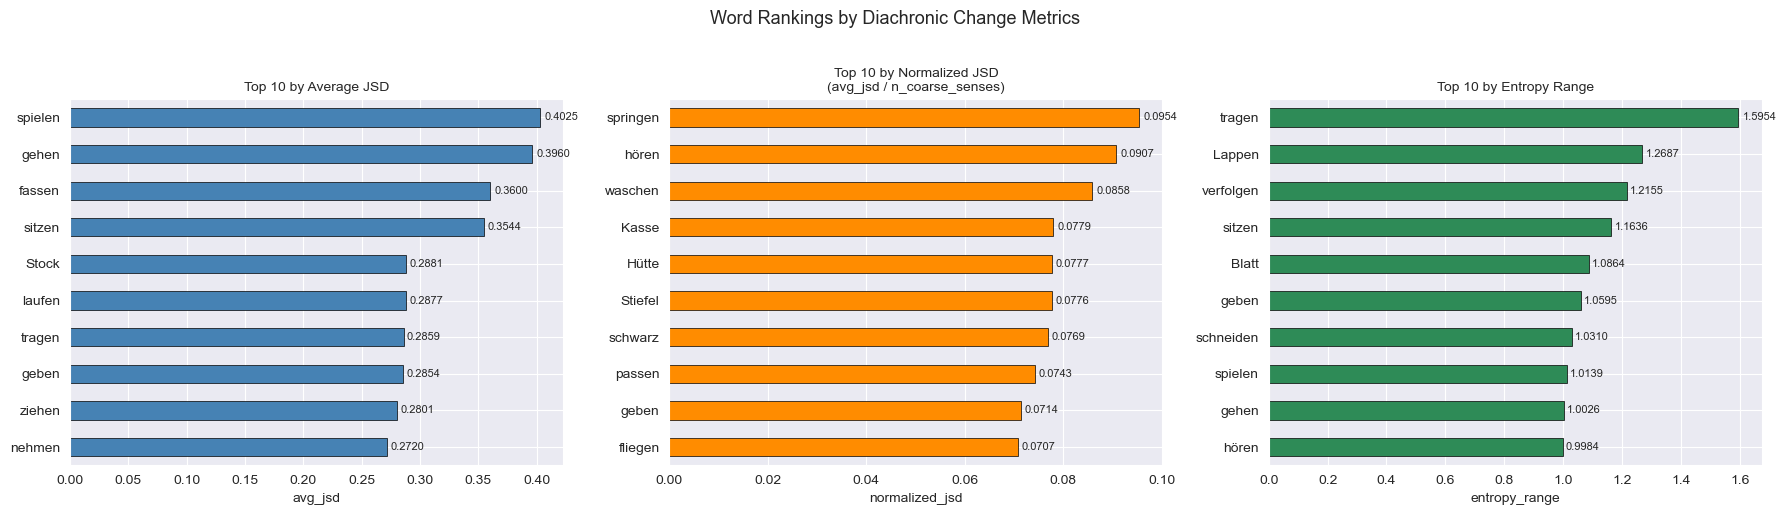

In [301]:
# Bar charts: top 10 by each ranking metric
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

panels = [
    (top10_jsd,    'avg_jsd',        'Average JSD',              'steelblue'),
    (top10_norm,   'normalized_jsd', 'Normalized JSD\n(avg_jsd / n_coarse_senses)', 'darkorange'),
    (top10_entropy,'entropy_range',  'Entropy Range',            'seagreen'),
]

for ax, (df, col, title, color) in zip(axes, panels):
    df[col].plot.barh(ax=ax, color=color, edgecolor='black', linewidth=0.5)
    ax.set_xlabel(col)
    ax.set_title(f'Top 10 by {title}', fontsize=10)
    ax.invert_yaxis()
    for i, (word, val) in enumerate(df[col].items()):
        ax.text(val + val * 0.01, i, f'{val:.4f}', va='center', fontsize=8)

plt.suptitle('Word Rankings by Diachronic Change Metrics', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Notable Words for Further Analysis

**Strong candidates (normalized JSD):**

springen, hören, waschen, Kasse, Stiefel
→ few senses, strong relative shifts, clean and interpretable

**Structured examples:**

Programm → gradual shift + emergence

Präsident → clear reweighting

**Complex / high-variability:**

tragen, sitzen, spielen
→ high polysemy, less clean patterns

**Less suitable:**

gehen, nehmen, geben
→ high variability rather than clear semantic change

**Conclusion:**
Focus on a mix of structured examples and normalized-JSD candidates for robust qualitative analysis.

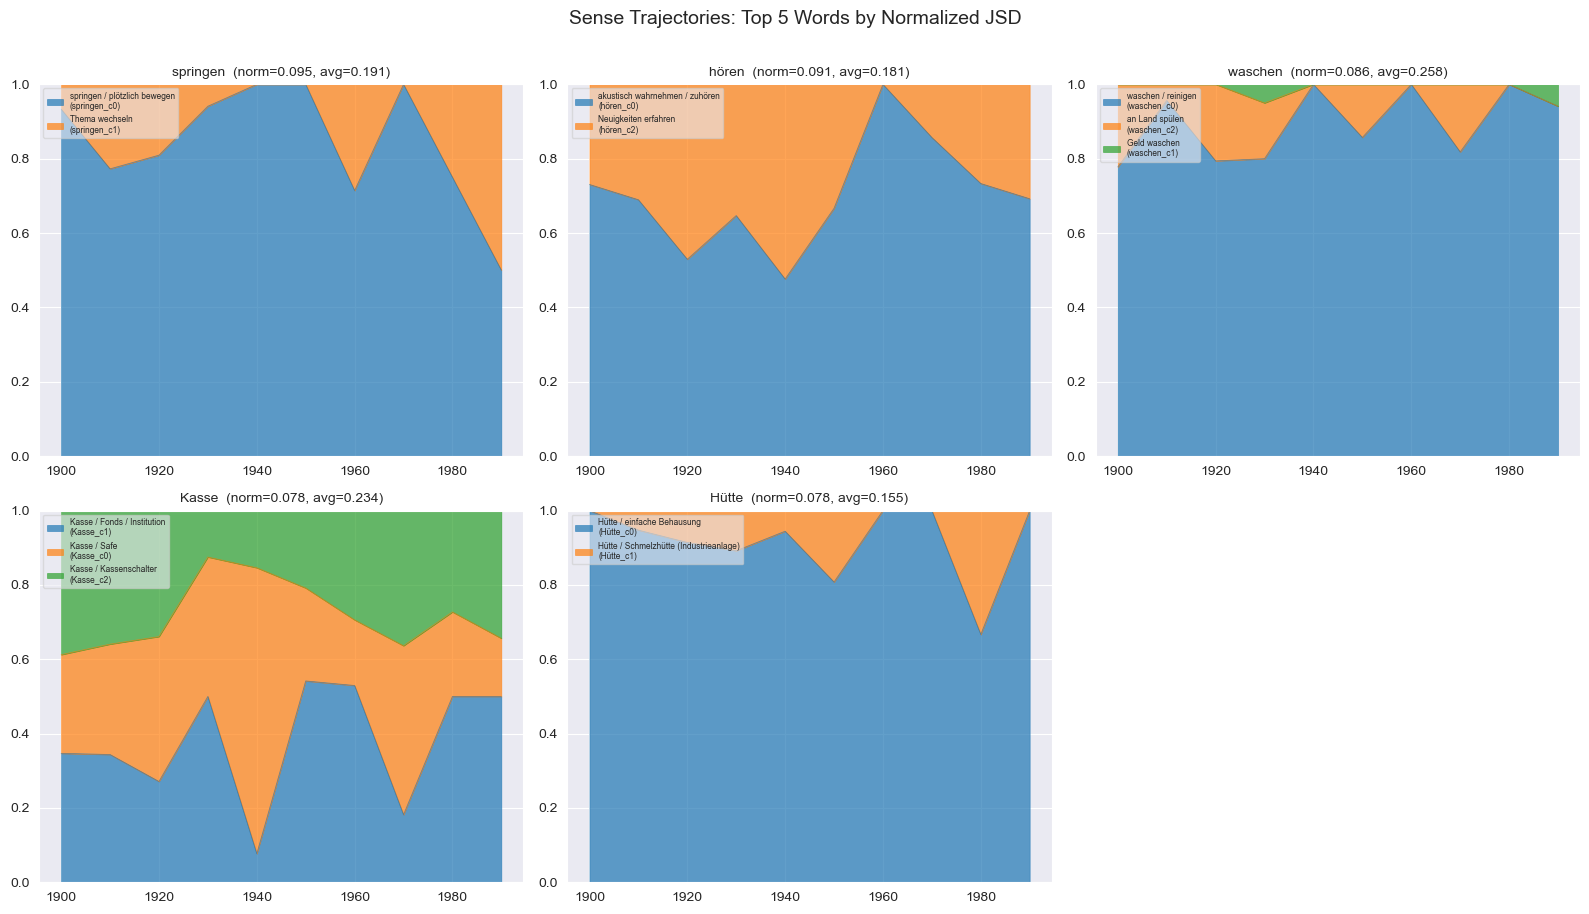

In [302]:
# Small-multiples: sense trajectories for top 5 by normalized JSD
TOP_N       = 5   # senses per subplot; remainder collapsed into 'Other'
top5_lemmas = top10_norm.head(5).index.tolist()
n_cols = 3
n_rows = (len(top5_lemmas) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4.5 * n_rows), squeeze=False)

for idx, lemma in enumerate(top5_lemmas):
    row, col = divmod(idx, n_cols)
    ax = axes[row][col]

    lc = sense_counts[sense_counts['lemma'] == lemma]
    if len(lc) == 0:
        ax.set_title(f'{lemma} (no data)')
        continue

    pivot = lc.pivot(index='decade', columns='predicted_sense_id', values='proportion').fillna(0)
    col_order = pivot.sum().sort_values(ascending=False).index
    pivot = pivot[col_order]

    # Collapse tail senses into 'Other'
    has_other = len(pivot.columns) > TOP_N
    if has_other:
        top_cols  = list(pivot.columns[:TOP_N])
        other_sum = pivot[pivot.columns[TOP_N:]].sum(axis=1)
        pivot = pivot[top_cols].copy()
        pivot['Other'] = other_sum

    # Relabel sense IDs
    sense_cols = [c for c in pivot.columns if c != 'Other']
    pivot.columns = list(relabel_index(lemma, sense_cols)) + (['Other'] if has_other else [])

    pivot.plot.area(ax=ax, alpha=0.7, linewidth=0.5)
    norm_val = top10_norm.loc[lemma, 'normalized_jsd']
    avg_val  = top10_norm.loc[lemma, 'avg_jsd']
    ax.set_title(f'{lemma}  (norm={norm_val:.3f}, avg={avg_val:.3f})', fontsize=10)
    ax.set_ylim(0, 1)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.legend(fontsize=6, loc='upper left', bbox_to_anchor=(0, 1),
              framealpha=0.6, ncol=1)

# Hide empty subplots
for idx in range(len(top5_lemmas), n_rows * n_cols):
    row, col = divmod(idx, n_cols)
    axes[row][col].set_visible(False)

fig.suptitle('Sense Trajectories: Top 5 Words by Normalized JSD', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 4. Temporal Change Metrics

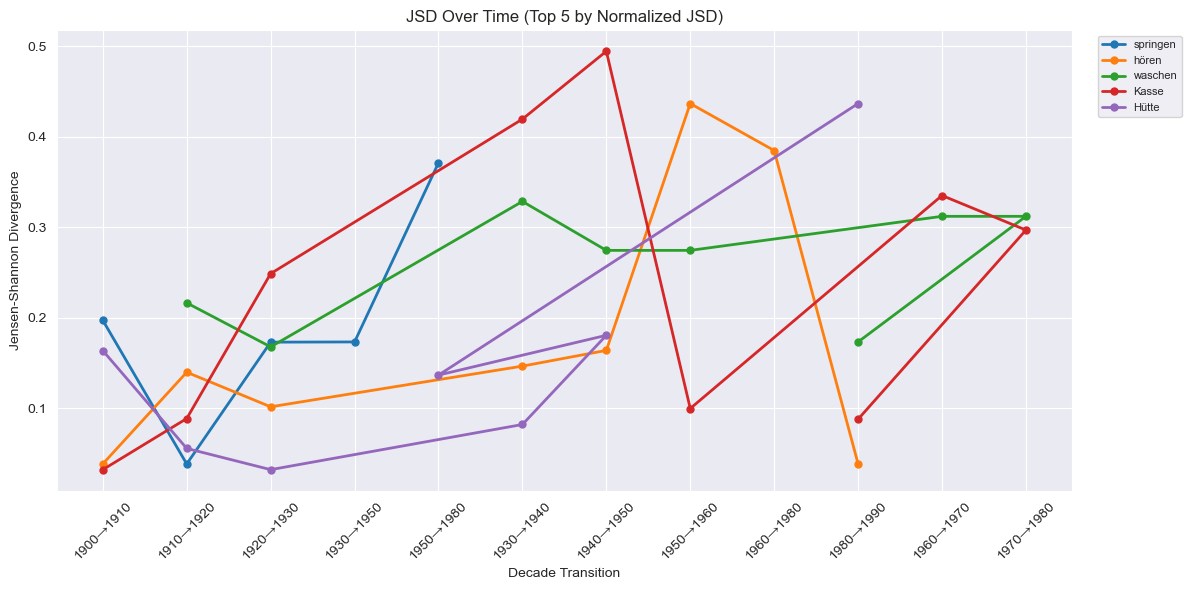

In [303]:
# JSD divergence over time for top words (normalized JSD ranking)
top_div_lemmas = top10_norm.head(5).index.tolist()

fig, ax = plt.subplots(figsize=(12, 6))
for lemma in top_div_lemmas:
    ld = divergence[divergence['lemma'] == lemma].sort_values('decade_from')
    transition_labels = [f"{int(r['decade_from'])}→{int(r['decade_to'])}" for _, r in ld.iterrows()]
    ax.plot(transition_labels, ld['jsd'].values, marker='o', label=lemma, linewidth=2, markersize=5)

ax.set_xlabel('Decade Transition')
ax.set_ylabel('Jensen-Shannon Divergence')
ax.set_title('JSD Over Time (Top 5 by Normalized JSD)')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

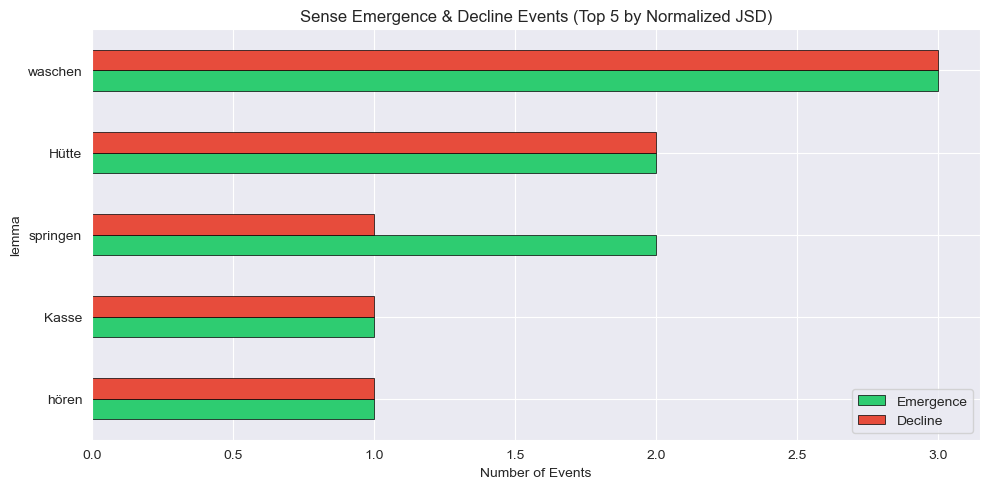

In [304]:
# Emergence & decline event counts for top words (normalized JSD ranking)
top_norm_lemmas = top10_norm.head(5).index.tolist()

emerg_counts_top = emergence[emergence['lemma'].isin(top_norm_lemmas)].groupby('lemma').size().rename('emergence')
decl_counts_top  = decline[decline['lemma'].isin(top_norm_lemmas)].groupby('lemma').size().rename('decline')
event_counts = (pd.concat([emerg_counts_top, decl_counts_top], axis=1)
                .fillna(0).astype(int)
                .reindex(top_norm_lemmas)
                .sort_values('emergence', ascending=True))

fig, ax = plt.subplots(figsize=(10, 5))
event_counts[['emergence', 'decline']].plot.barh(
    ax=ax, color=['#2ecc71', '#e74c3c'], edgecolor='black', linewidth=0.5
)
ax.set_xlabel('Number of Events')
ax.set_title('Sense Emergence & Decline Events (Top 5 by Normalized JSD)')
ax.legend(['Emergence', 'Decline'])
plt.tight_layout()
plt.show()

In [305]:
# Flag suspicious JSD=1.0 events with context counts
jsd_max = divergence[divergence['jsd'] >= 0.99].copy()

if len(jsd_max) > 0:
    # Annotate with context counts from decade_stats
    stats_lookup = decade_stats.set_index(['lemma', 'decade'])['n_contexts']
    jsd_max['n_contexts_from'] = jsd_max.apply(
        lambda r: stats_lookup.get((r['lemma'], r['decade_from']), 0), axis=1
    )
    jsd_max['n_contexts_to'] = jsd_max.apply(
        lambda r: stats_lookup.get((r['lemma'], r['decade_to']), 0), axis=1
    )
    jsd_max['min_contexts'] = jsd_max[['n_contexts_from', 'n_contexts_to']].min(axis=1)

    display(Markdown(f'### JSD >= 0.99 Events ({len(jsd_max)} total)'))
    display(
        jsd_max[['lemma', 'decade_from', 'decade_to', 'jsd', 'n_contexts_from', 'n_contexts_to', 'min_contexts']]
        .sort_values('min_contexts')
        .style.background_gradient(subset=['min_contexts'], cmap='RdYlGn')
        .format({'jsd': '{:.4f}'})
        .set_properties(**{'text-align': 'center'})
    )
else:
    print('No JSD >= 0.99 events found.')

No JSD >= 0.99 events found.


## 5. Sparse Data Audit

Many dramatic JSD=1.0 values may be artifacts of sparse data. This section investigates.

In [306]:
# Annotate ALL divergence rows with context counts
stats_lookup = decade_stats.set_index(['lemma', 'decade'])['n_contexts']

div_annotated = divergence.copy()
div_annotated['n_contexts_from'] = div_annotated.apply(
    lambda r: stats_lookup.get((r['lemma'], r['decade_from']), 0), axis=1
)
div_annotated['n_contexts_to'] = div_annotated.apply(
    lambda r: stats_lookup.get((r['lemma'], r['decade_to']), 0), axis=1
)
div_annotated['min_contexts'] = div_annotated[['n_contexts_from', 'n_contexts_to']].min(axis=1)

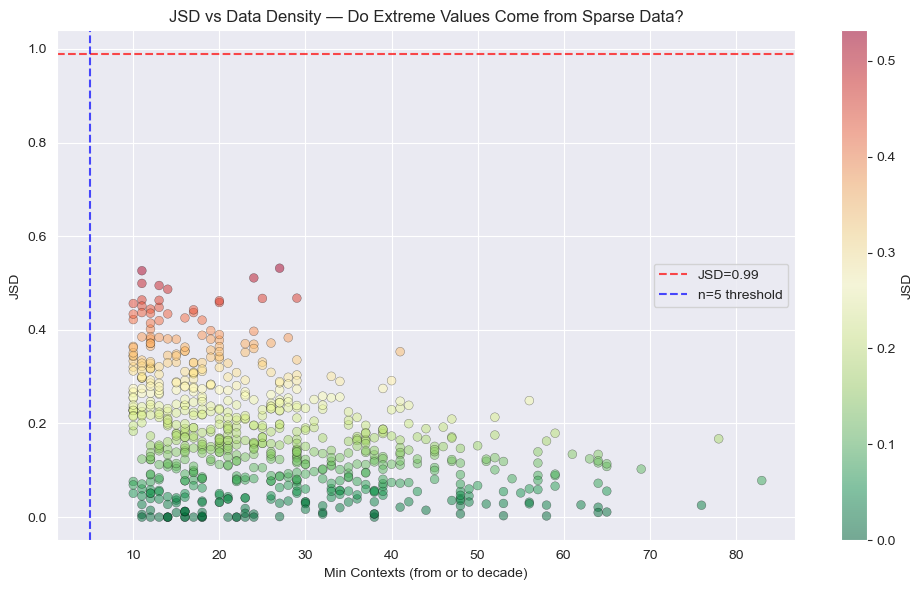

Correlation (min_contexts vs JSD): -0.381


In [307]:
# Scatter: JSD vs min(n_contexts)
fig, ax = plt.subplots(figsize=(10, 6))
scatter = ax.scatter(
    div_annotated['min_contexts'], div_annotated['jsd'],
    alpha=0.5, c=div_annotated['jsd'], cmap='RdYlGn_r', edgecolors='black', linewidth=0.3, s=40
)
ax.axhline(y=0.99, color='red', linestyle='--', alpha=0.7, label='JSD=0.99')
ax.axvline(x=5, color='blue', linestyle='--', alpha=0.7, label='n=5 threshold')
ax.set_xlabel('Min Contexts (from or to decade)')
ax.set_ylabel('JSD')
ax.set_title('JSD vs Data Density — Do Extreme Values Come from Sparse Data?')
ax.legend()
plt.colorbar(scatter, ax=ax, label='JSD')
plt.tight_layout()
plt.show()

# Correlation
corr = div_annotated[['min_contexts', 'jsd']].corr().iloc[0, 1]
print(f'Correlation (min_contexts vs JSD): {corr:.3f}')

Divergence values decrease with increasing data density, but meaningful variation remains across well-supported observations, indicating that semantic change signals are not merely artifacts of sparse data.

In [273]:
# List word-decades with < 5 contexts
sparse_wd = decade_stats[decade_stats['n_contexts'] < 5][['lemma', 'decade', 'n_contexts', 'n_senses', 'dominant_sense']]
sparse_wd = sparse_wd.sort_values(['n_contexts', 'lemma'])

display(Markdown(f'### Word-Decades with < 5 Contexts ({len(sparse_wd)} total)'))
display(sparse_wd.style.set_properties(**{'text-align': 'center'}))

### Word-Decades with < 5 Contexts (8 total)

,lemma,decade,n_contexts,n_senses,dominant_sense
742,schneiden,1980,1,1,schneiden_c1
751,schwarz,1970,2,2,schwarz_c2
861,wild,1970,3,2,wild_c0
62,Blatt,1970,4,3,Blatt_c2
602,gehen,1980,4,3,gehen_c8
730,schlagen,1960,4,3,schlagen_c7
772,sitzen,1980,4,2,sitzen_c4
801,springen,1970,4,1,springen_c0


In [274]:
# Reliability assessment
n_jsd_high = (div_annotated['jsd'] >= 0.99).sum()
n_jsd_high_sparse = ((div_annotated['jsd'] >= 0.99) & (div_annotated['min_contexts'] < 5)).sum()
n_jsd_high_reliable = ((div_annotated['jsd'] >= 0.99) & (div_annotated['min_contexts'] >= 5)).sum()

display(Markdown('### Reliability Summary'))
display(Markdown(
    f'- **JSD >= 0.99 events:** {n_jsd_high}\n'
    f'- **Of those, with min_contexts < 5 (likely artifacts):** {n_jsd_high_sparse} '
    f'({n_jsd_high_sparse/max(n_jsd_high,1)*100:.0f}%)\n'
    f'- **Of those, with min_contexts >= 5 (potentially real):** {n_jsd_high_reliable} '
    f'({n_jsd_high_reliable/max(n_jsd_high,1)*100:.0f}%)\n\n'
    f'**Recommendation:** Treat JSD values from word-decades with < 5 contexts as unreliable. '
    f'Focus manual validation on high-JSD events where both decades have >= 5 contexts.'
))

### Reliability Summary

- **JSD >= 0.99 events:** 0
- **Of those, with min_contexts < 5 (likely artifacts):** 0 (0%)
- **Of those, with min_contexts >= 5 (potentially real):** 0 (0%)

**Recommendation:** Treat JSD values from word-decades with < 5 contexts as unreliable. Focus manual validation on high-JSD events where both decades have >= 5 contexts.

### Case Selection Criteria

Words are selected for detailed diachronic inspection according to four criteria, applied in combination to balance quantitative rigor with qualitative interpretability.

- **Sufficient data coverage.** The word must have at least 100 total contexts across all decades and must be present in at least 8 of 10 decades with a minimum of 10 contexts per decade. Words falling below these thresholds cannot support reliable per-decade sense distributions and are excluded regardless of their apparent change signal.
- **Non-trivial polysemy.** The word must be assigned to more than one active coarse-grained sense cluster across the pilot period. Effectively monosemous words produce JSD values near zero and offer no meaningful diachronic signal.
- **Strong and consistent change signal.** The word's average JSD must fall in the top quartile of the distribution across all eligible words, and at least one sense must display a monotonic trajectory with Spearman |ρ| ≥ 0.6. A high average JSD alone is insufficient if the change is confined to a single noisy transition; sustained, directional shifts are preferred.
- **Qualitative interpretability.** Preference is given to words where the dominant shift plausibly corresponds to a historical, cultural, or semantic development — such as the emergence or decline of a sense that can be linked to documented change in German society or language. Words where the predicted trend is more likely attributable to genre drift, corpus imbalance, or systematic WSD error are deprioritised.

Words meeting all four criteria are classified as strong candidates; those meeting three are classified as marginal. Final selection integrates both the quantitative scores reported below and a qualitative reading of the sense trajectories.

## 6. WWII Era Patterns

Focus on 1930s &rarr; 1940s &rarr; 1950s transitions.

The DWDS kern corpus contains texts from 1900–1999. The 1930s→1940s and 1940s→1950s transitions coincide with WWII and the immediate post-war period — a time of significant social and linguistic change in German.

Several words show unusually high JSD in this window. Hypothesized patterns:
- **Sense consolidation during the war** — language simplification, propaganda, restricted discourse
- **Post-war diversification** — new senses emerging in the 1950s as society and language opened up

**Caveat:** The 1940s is also one of the sparser decades in the corpus (fewer published texts), so some of these signals may still be data artifacts even after filtering. The context examples below are the most direct way to judge.

### Top 15 Words by WWII-Era Avg JSD

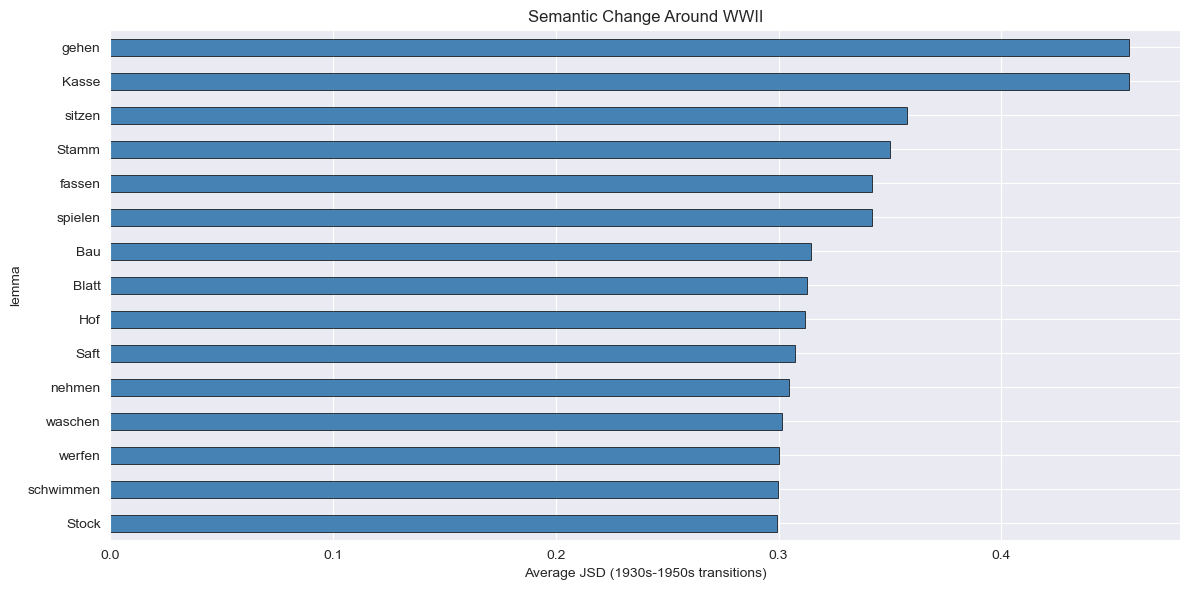

In [275]:
# Top words by WWII-era divergence
wwii_decades = [1930, 1940, 1950]
wwii_div = divergence[
    divergence['decade_from'].isin(wwii_decades) &
    divergence['decade_to'].isin(wwii_decades)
].copy()

wwii_avg = wwii_div.groupby('lemma')['jsd'].mean().sort_values(ascending=False)

display(Markdown('### Top 15 Words by WWII-Era Avg JSD'))

fig, ax = plt.subplots(figsize=(12, 6))
wwii_avg.head(15).plot.barh(ax=ax, color='steelblue', edgecolor='black', linewidth=0.5)
ax.set_xlabel('Average JSD (1930s-1950s transitions)')
ax.set_title('Semantic Change Around WWII')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

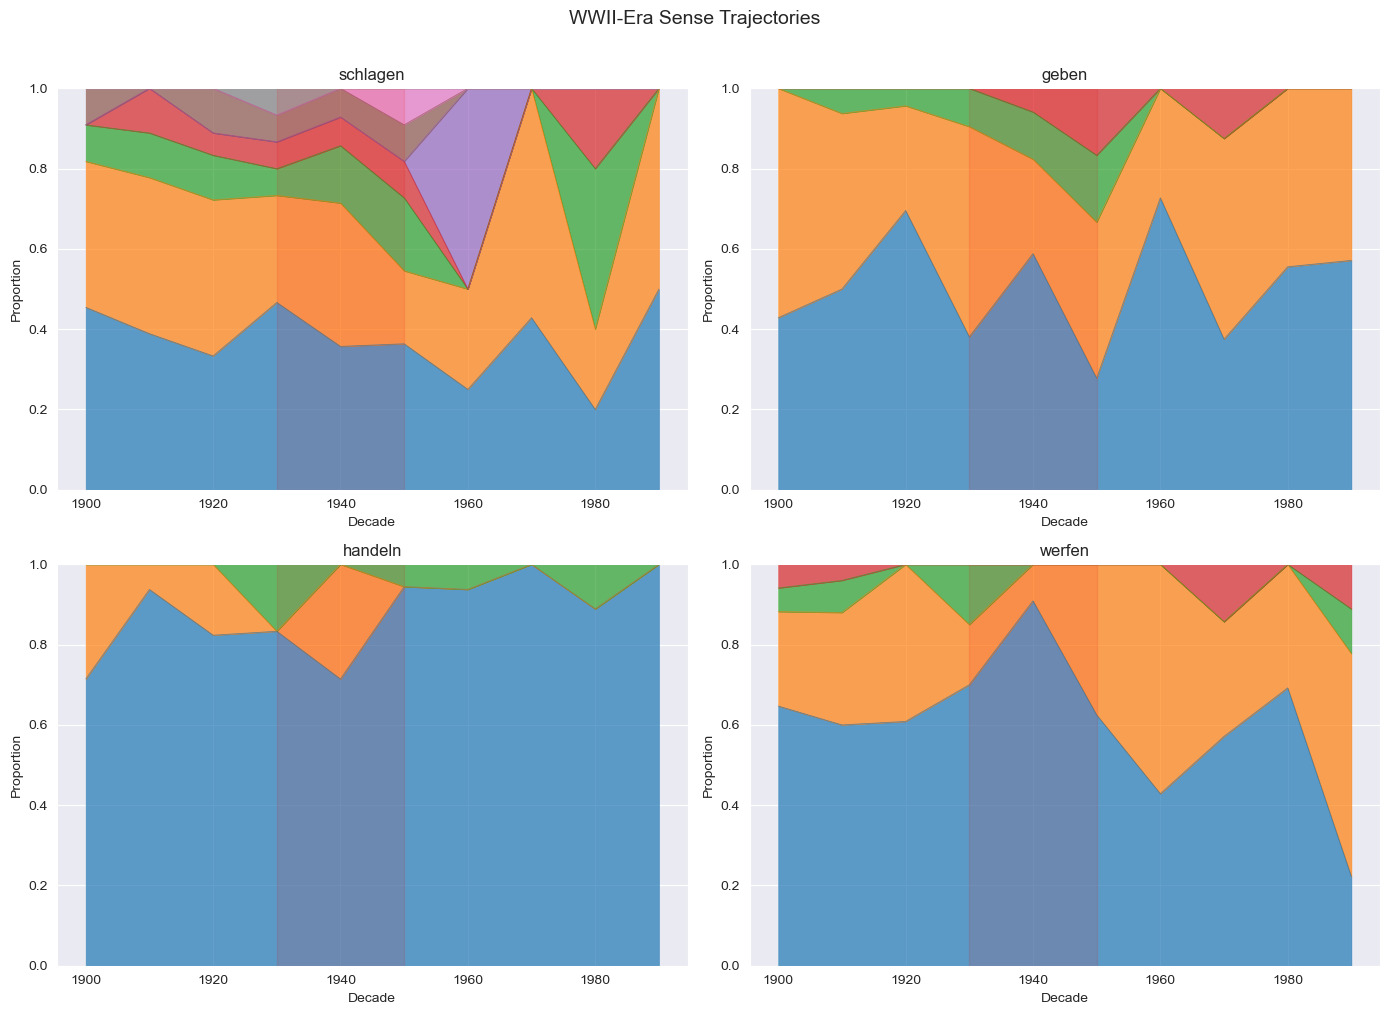

In [276]:
# Sense trajectories for key WWII-era words
wwii_focus_words = ['schlagen', 'geben', 'handeln', 'werfen']
# Filter to words that actually exist in the data
wwii_focus_words = [w for w in wwii_focus_words if w in sense_counts['lemma'].values]

if wwii_focus_words:
    n_cols = 2
    n_rows = (len(wwii_focus_words) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 5 * n_rows), squeeze=False)

    for idx, lemma in enumerate(wwii_focus_words):
        row, col = divmod(idx, n_cols)
        ax = axes[row][col]

        lc = sense_counts[sense_counts['lemma'] == lemma]
        if len(lc) == 0:
            ax.set_title(f'{lemma} (no data)')
            continue

        pivot = lc.pivot(index='decade', columns='predicted_sense_id', values='proportion').fillna(0)
        col_order = pivot.sum().sort_values(ascending=False).index
        pivot = pivot[col_order]
        pivot.plot.area(ax=ax, alpha=0.7, linewidth=0.5, legend=False)

        # Highlight WWII decades
        ax.axvspan(1930, 1950, alpha=0.1, color='red', label='WWII era')
        ax.set_title(f'{lemma}', fontsize=12)
        ax.set_ylim(0, 1)
        ax.set_xlabel('Decade')
        ax.set_ylabel('Proportion')

    for idx in range(len(wwii_focus_words), n_rows * n_cols):
        row, col = divmod(idx, n_cols)
        axes[row][col].set_visible(False)

    fig.suptitle('WWII-Era Sense Trajectories', fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()
else:
    print('None of the WWII focus words found in data.')

In [277]:
# Context examples: 1930s vs 1940s for WWII focus words
if wwii_focus_words:
    for lemma in wwii_focus_words:
        preds_lemma = predictions[predictions['lemma'] == lemma]
        display(Markdown(f'### {lemma}: 1930s vs 1940s Contexts'))

        for dec in [1930, 1940]:
            dec_preds = preds_lemma[preds_lemma['decade'] == dec]
            if len(dec_preds) == 0:
                display(Markdown(f'*No {dec}s contexts*'))
                continue

            display(Markdown(f'**{dec}s** ({len(dec_preds)} contexts):'))
            samples = dec_preds.sample(n=min(3, len(dec_preds)), random_state=42)
            for _, row in samples.iterrows():
                sense_info = f"{row['predicted_sense_id']}"
                if 'sense_class' in row and pd.notna(row.get('sense_class')):
                    sense_info += f" ({row['sense_class']})"
                sent = str(row['sentence'])[:250] + ('...' if len(str(row['sentence'])) > 250 else '')
                display(Markdown(f'- [{sense_info}, conf={row["confidence"]:.3f}] *{sent}*'))

### schlagen: 1930s vs 1940s Contexts

**1930s** (15 contexts):

- [schlagen_c0, conf=0.842] *Erst als sie der Arm des Lichtes erreicht und als er seine Krallen in ihre Augen schlägt, werfen auch sie sich nieder und spüren plötzlich das Herz durch die Rippen und durch den Rock hindurch gegen die Erde schlagen wie gegen das Fell einer Trommel.*

- [schlagen_c5, conf=0.844] *Und Bilfinger ist Deutscher, nur Deutscher, nur eins mit denen, die schlagen.*

- [schlagen_c0, conf=0.827] *Schon senkte sich ein Ast ins Wasser, und von besinnungsloser Zerstörungswut ergriffen, umringten die Gefährten Bernardinos andere Bäume und machten sich an die Holzfällerarbeit, als gälte es einfach, einen Wald zu schlagen.*

...

- [werfen_c1, conf=0.858] *Man kann ebenso Gegenstände neben das lichtempfindliche Papier stellen und mit Hilfe eines Projektionsapparates aus derselben Richtung her den Schatten des betreffenden Gegenstandes auf das lichtempfindliche Papier werfen.*

**1940s** (11 contexts):

- [werfen_c2, conf=0.836] *'Tretet ein, auch hier sind Götter.' Diese Worte werfen ihr Licht auf unseren Weg durch die griechische Philosophie« (W. Jaeger).*

- [werfen_c0, conf=0.858] *Zu diesem Zwecke werfen wir sie in kochendes Wasser.*

- [werfen_c0, conf=0.831] *»Sie wünschen also«, fragte Borromeo mit Bitterkeit, »daß wir die Grundlagen unseres Programms über Bord werfen.«*

## 7. Case Study Candidates

Select words suitable for a diachronic case study. Selection criteria (all must hold):

1. **Large change** — normalized JSD (`avg_jsd / n_coarse_senses`) in top quartile; penalises high-polysemy words where distributional spread is partly structural
2. **Monotonic trend** — at least one sense shows a sustained directional shift (Spearman |ρ| ≥ 0.6 over decades)
3. **Dense data** — ≥ 8 of 10 decades present with ≥ 10 contexts each

Words that pass all three criteria are flagged as **strong** candidates. Words passing 2/3 are **marginal**.

In [278]:
from scipy.stats import spearmanr

ALL_DECADES = list(range(1900, 2000, 10))  # 10 reference decades

# ── Criterion 1: normalized JSD (top quartile) ───────────────────────────────
avg_jsd_coarse    = divergence.groupby('lemma')['jsd'].mean()
n_senses_coarse   = sense_counts.groupby('lemma')['predicted_sense_id'].nunique()
norm_jsd_coarse   = (avg_jsd_coarse / n_senses_coarse.replace(0, pd.NA)).dropna()
jsd_threshold     = norm_jsd_coarse.quantile(0.75)

# ── Criterion 2: monotonicity — max |Spearman ρ| across all senses ───────────
def monotonicity_score(lemma: str) -> tuple[float, str]:
    """Return (max |ρ|, sense_id) for the most monotonic sense of this lemma."""
    lc = sense_counts[sense_counts['lemma'] == lemma]
    best_rho, best_sense = 0.0, ''
    for sense_id, grp in lc.groupby('predicted_sense_id'):
        grp = grp.set_index('decade').reindex(ALL_DECADES)
        proportions = grp['proportion'].values
        valid = ~pd.isna(proportions)
        if valid.sum() < 6:
            continue
        decades_valid = [ALL_DECADES[i] for i in range(10) if valid[i]]
        props_valid   = proportions[valid]
        rho, _ = spearmanr(decades_valid, props_valid)
        if abs(rho) > abs(best_rho):
            best_rho, best_sense = rho, sense_id
    return round(best_rho, 3), best_sense

mono_results = {lemma: monotonicity_score(lemma) for lemma in norm_jsd_coarse.index}
mono_rho   = pd.Series({l: v[0] for l, v in mono_results.items()})
mono_sense = pd.Series({l: v[1] for l, v in mono_results.items()})

# ── Criterion 3: data density ─────────────────────────────────────────────────
decade_coverage = (decade_stats[decade_stats['n_contexts'] >= 10]
                   .groupby('lemma')['decade'].count()
                   .reindex(norm_jsd_coarse.index, fill_value=0))

# ── Build candidate table ─────────────────────────────────────────────────────
candidates = pd.DataFrame({
    'normalized_jsd':  norm_jsd_coarse,
    'avg_jsd':         avg_jsd_coarse.reindex(norm_jsd_coarse.index),
    'n_senses':        n_senses_coarse.reindex(norm_jsd_coarse.index),
    'mono_rho':        mono_rho.abs(),
    'mono_rho_signed': mono_rho,
    'mono_sense':      mono_sense,
    'dense_decades':   decade_coverage,
}).sort_values('normalized_jsd', ascending=False)

candidates['c1_large_change'] = candidates['normalized_jsd'] >= jsd_threshold
candidates['c2_monotonic']    = candidates['mono_rho']        >= 0.6
candidates['c3_dense']        = candidates['dense_decades']   >= 8
candidates['criteria_met']    = candidates[['c1_large_change', 'c2_monotonic', 'c3_dense']].sum(axis=1)
candidates['strength']        = candidates['criteria_met'].map({3: 'STRONG', 2: 'marginal', 1: 'weak', 0: 'weak'})

display(Markdown(f'### Candidate Scoring (top 20 by normalized JSD, threshold={jsd_threshold:.4f})'))
cols = ['normalized_jsd', 'avg_jsd', 'n_senses', 'mono_rho', 'mono_sense', 'dense_decades',
        'c1_large_change', 'c2_monotonic', 'c3_dense', 'criteria_met', 'strength']
display(
    candidates.head(20)[cols].style
    .format({'normalized_jsd': '{:.4f}', 'avg_jsd': '{:.4f}', 'mono_rho': '{:.3f}', 'dense_decades': '{:.0f}'})
    .map(lambda v: 'background-color: #d4edda' if v is True else
                   ('background-color: #f8d7da' if v is False else ''),
         subset=['c1_large_change', 'c2_monotonic', 'c3_dense'])
    .map(lambda v: 'font-weight: bold; color: darkgreen' if v == 'STRONG' else
                   ('color: darkorange' if v == 'marginal' else ''),
         subset=['strength'])
    .set_properties(**{'text-align': 'center'})
)

strong   = candidates[candidates['strength'] == 'STRONG'].index.tolist()
marginal = candidates[candidates['strength'] == 'marginal'].index.tolist()
print(f'\nStrong candidates ({len(strong)}):  {strong}')
print(f'Marginal candidates ({len(marginal)}): {marginal[:10]}')

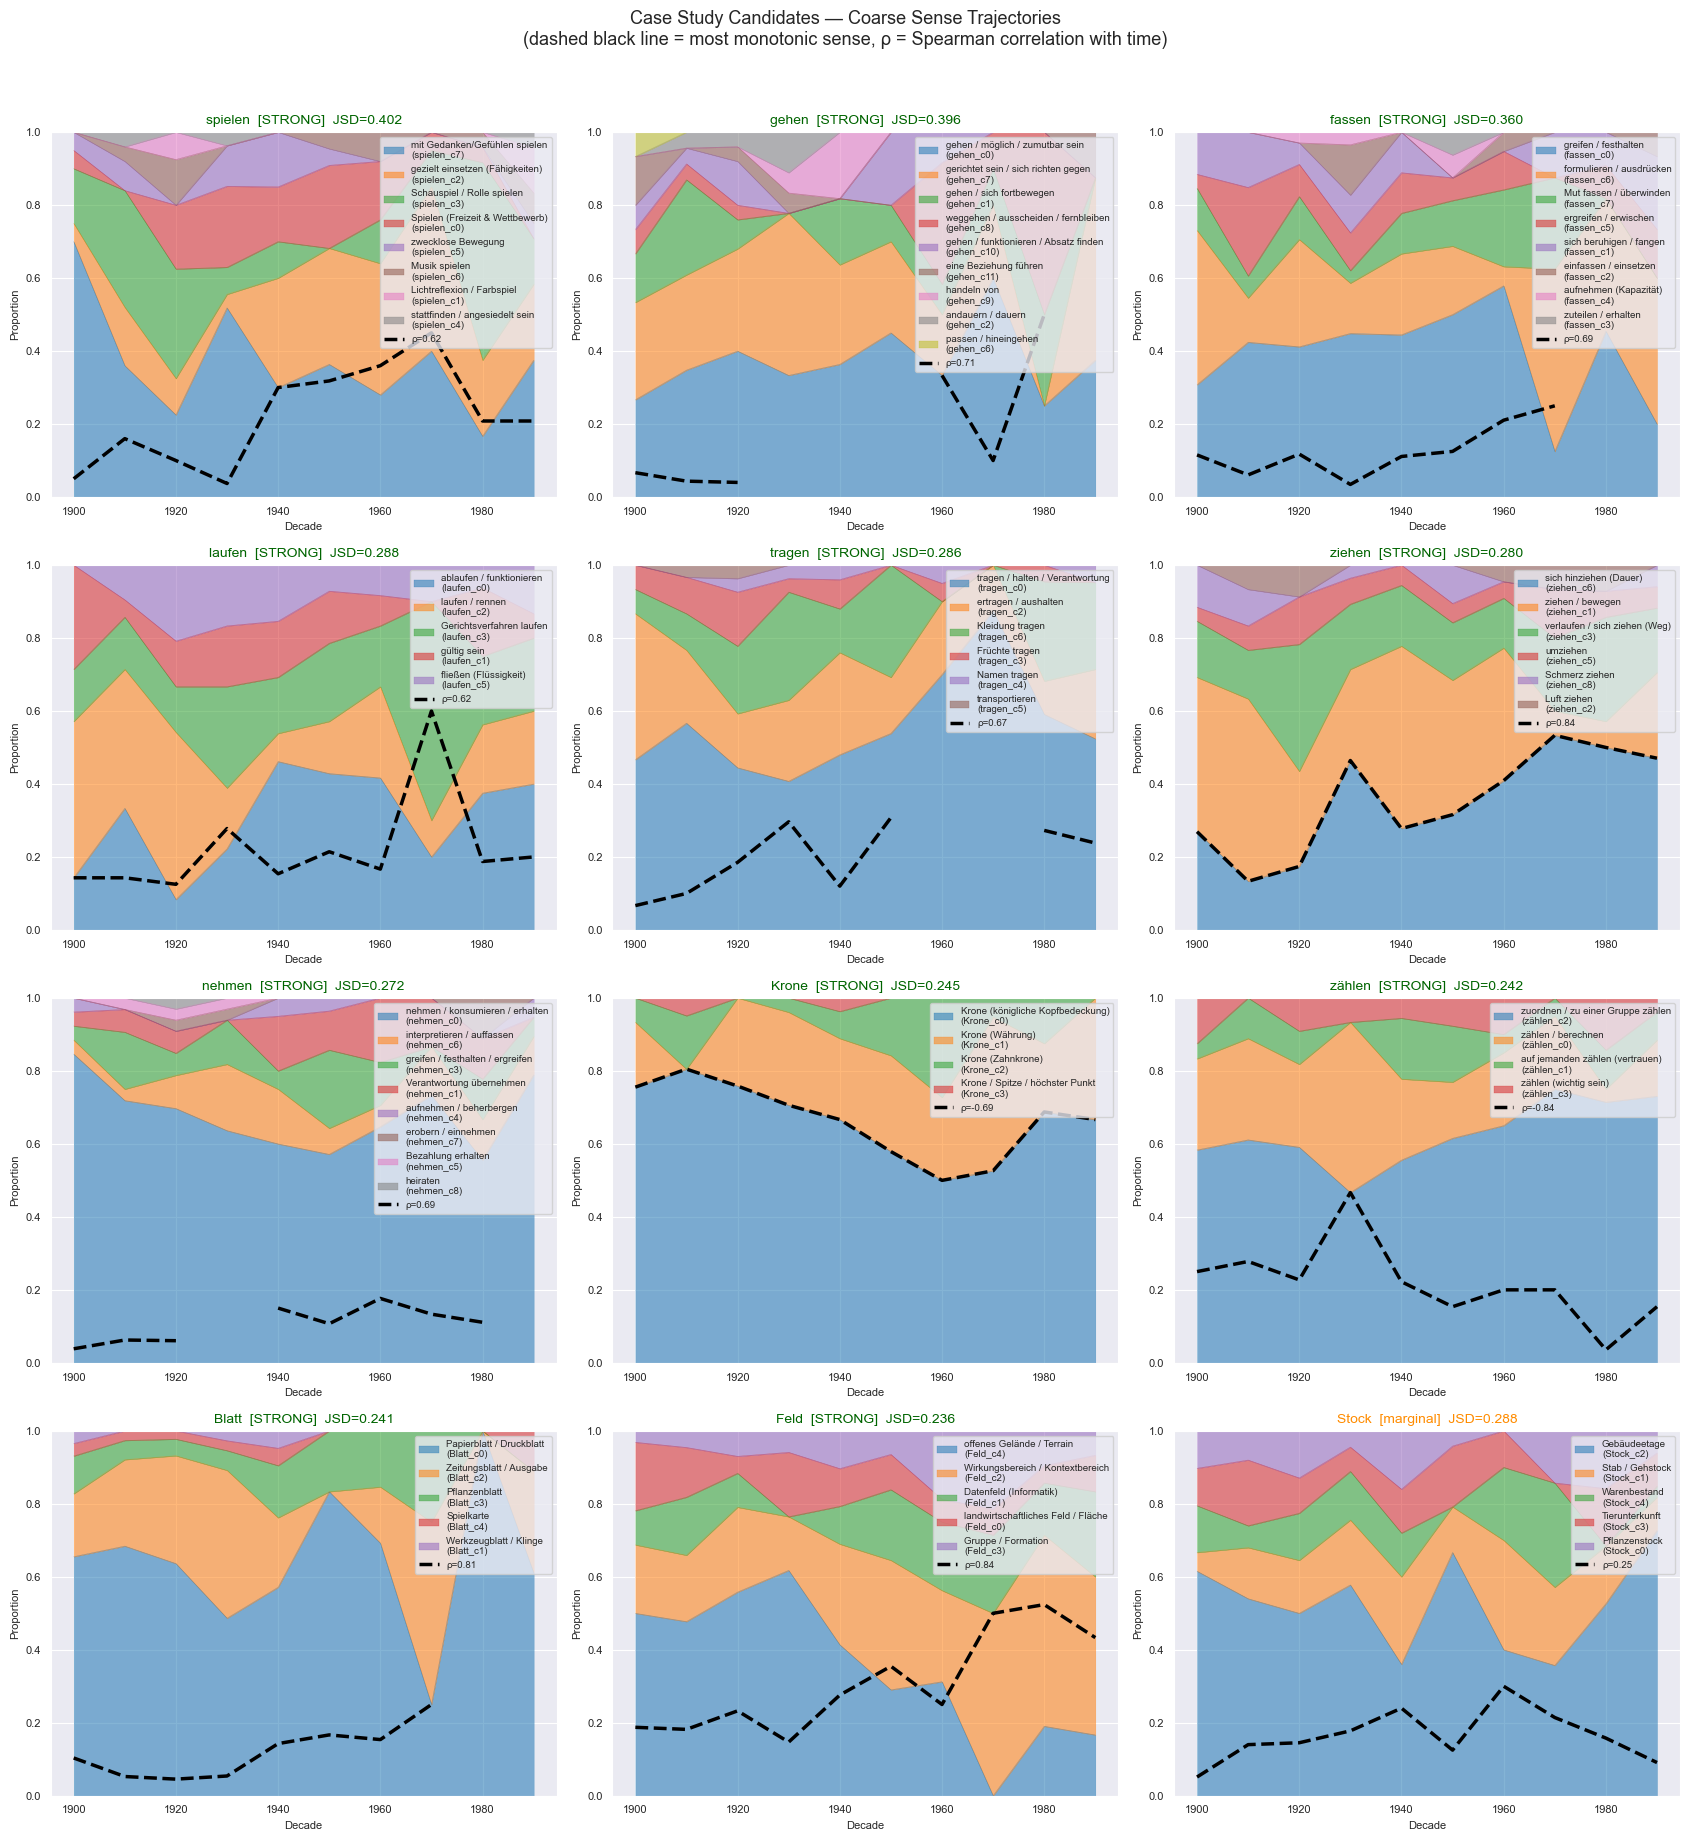

In [279]:
# Sense trajectories for strong + top marginal candidates
# Each subplot: stacked area (proportions) + line for the most monotonic sense
plot_words = (strong + [w for w in marginal if w in candidates.head(20).index])[:12]

n_cols = 3
n_rows = (len(plot_words) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(17, 4.5 * n_rows), squeeze=False)

for idx, lemma in enumerate(plot_words):
    row, col = divmod(idx, n_cols)
    ax = axes[row][col]

    lc = sense_counts[sense_counts['lemma'] == lemma]
    if len(lc) == 0:
        ax.set_title(f'{lemma} (no data)')
        continue

    pivot = lc.pivot(index='decade', columns='predicted_sense_id', values='proportion').fillna(0)
    col_order = pivot.sum().sort_values(ascending=False).index
    pivot = pivot[col_order]
    pivot.columns = relabel_index(lemma, pivot.columns)
    pivot.plot.area(ax=ax, alpha=0.55, linewidth=0.3, legend=False)

    # Overlay the most monotonic sense as a thick line
    top_sense = candidates.loc[lemma, 'mono_sense']
    if top_sense and top_sense in lc['predicted_sense_id'].values:
        ts_data = lc[lc['predicted_sense_id'] == top_sense].set_index('decade')['proportion'].reindex(ALL_DECADES)
        ax.plot(ALL_DECADES, ts_data.values, color='black', linewidth=2.5,
                linestyle='--', label=f'ρ={candidates.loc[lemma, "mono_rho_signed"]:.2f}')
        ax.legend(fontsize=7, loc='upper right')

    strength_str = candidates.loc[lemma, 'strength']
    color = 'darkgreen' if strength_str == 'STRONG' else 'darkorange'
    jsd_val = candidates.loc[lemma, 'avg_jsd']
    ax.set_title(f'{lemma}  [{strength_str}]  JSD={jsd_val:.3f}', fontsize=10, color=color)
    ax.set_ylim(0, 1)
    ax.set_xlabel('Decade', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.tick_params(labelsize=8)

for idx in range(len(plot_words), n_rows * n_cols):
    row, col = divmod(idx, n_cols)
    axes[row][col].set_visible(False)

fig.suptitle('Case Study Candidates — Coarse Sense Trajectories\n'
             '(dashed black line = most monotonic sense, ρ = Spearman correlation with time)',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## Limitations and Sources of Uncertainty

Several sources of error may affect the reliability of the results reported here. WSD predictions are made at the sentence level with a coarse atemporal accuracy of approximately 80%, meaning that roughly one in five sense assignments is incorrect. These errors propagate into the decade-level sense distributions. As a consequence, JSD values, entropy estimates, and emergence or decline events may partly reflect misclassification rather than genuine linguistic change. Additionally, the coarse clustering step — while necessary to improve statistical reliability — merges fine-grained sense distinctions that may be relevant for diachronic analysis. Senses that were clearly distinct in the original GermaNet inventory are treated as equivalent within the same cluster, which can suppress or distort shifts occurring at a finer level of granularity. Confidence scores, though available per prediction, are not fully integrated into the metric computation; they are reported as diagnostics but do not weight individual observations in the distributions.

Second, the DWDS kern corpus exhibits uneven temporal coverage: earlier decades (1910s–1930s) contain substantially more contexts than later ones, and genre composition shifts across the century (e.g., decreasing fiction, increasing scientific writing). These structural properties of the corpus can introduce systematic biases into observed trends, particularly for senses whose usage is genre-sensitive. Low-frequency senses are especially vulnerable: a sense predicted in only a handful of instances in a given decade may appear to emerge or disappear due to sampling variation rather than actual change in usage. The results presented here are exploratory and should be treated as indicative of possible patterns, not as conclusive evidence of semantic change. Future work should address these limitations through improved WSD accuracy, better-calibrated uncertainty estimates, and the use of larger, more temporally and genre-balanced diachronic corpora.

In [308]:
# Final verdict table — each candidate annotated with the direction of its key shift
def describe_shift(lemma: str) -> str:
    """Summarise the direction of the most monotonic sense's shift."""
    top_sense = candidates.loc[lemma, 'mono_sense']
    rho = candidates.loc[lemma, 'mono_rho_signed']
    label_str = sense_label(lemma, top_sense) if top_sense else '?'
    direction = 'rising' if rho > 0 else 'declining'
    return f'{label_str}  →  {direction} (ρ={rho:+.2f})'

verdict_lemmas = strong + [w for w in marginal if w in candidates.head(20).index]
verdict = candidates.loc[verdict_lemmas, ['avg_jsd', 'mono_rho', 'dense_decades', 'criteria_met', 'strength']].copy()
verdict['dominant_shift'] = [describe_shift(l) for l in verdict.index]
verdict['total_contexts'] = (decade_stats_coarse.groupby('lemma')['n_contexts']
                              .sum().reindex(verdict.index))

display(Markdown('### Final Verdict: Case Study Shortlist'))
display(
    verdict[['avg_jsd', 'mono_rho', 'dense_decades', 'total_contexts', 'strength', 'dominant_shift']].style
    .format({'avg_jsd': '{:.4f}', 'mono_rho': '{:.3f}',
             'dense_decades': '{:.0f}', 'total_contexts': '{:.0f}'})
    .map(lambda v: 'font-weight: bold; color: darkgreen' if v == 'STRONG' else
                   ('color: darkorange' if v == 'marginal' else ''),
         subset=['strength'])
    .set_properties(**{'text-align': 'left'})
    .set_properties(**{'text-align': 'center'},
                    subset=['avg_jsd', 'mono_rho', 'dense_decades', 'total_contexts', 'strength'])
)

### Final Verdict: Case Study Shortlist

,avg_jsd,mono_rho,dense_decades,total_contexts,strength,dominant_shift
spielen,0.4025,0.620,10,247,STRONG,gezielt einsetzen (Fähigkeiten) (spielen_c2) → rising (ρ=+0.62)
gehen,0.3960,0.714,8,146,STRONG,weggehen / ausscheiden / fernbleiben (gehen_c8) → rising (ρ=+0.71)
fassen,0.3600,0.690,9,209,STRONG,Mut fassen / überwinden (fassen_c7) → rising (ρ=+0.69)
laufen,0.2877,0.620,10,157,STRONG,Gerichtsverfahren laufen (laufen_c3) → rising (ρ=+0.62)
tragen,0.2859,0.667,10,229,STRONG,Kleidung tragen (tragen_c6) → rising (ρ=+0.67)
ziehen,0.2801,0.842,10,212,STRONG,sich hinziehen (Dauer) (ziehen_c6) → rising (ρ=+0.84)
nehmen,0.2720,0.690,9,232,STRONG,Verantwortung übernehmen (nehmen_c1) → rising (ρ=+0.69)
Krone,0.2454,0.693,10,287,STRONG,Krone (königliche Kopfbedeckung) (Krone_c0) → declining (ρ=-0.69)
zählen,0.2418,0.841,10,204,STRONG,zählen / berechnen (zählen_c0) → declining (ρ=-0.84)
Blatt,0.2406,0.810,8,224,STRONG,Pflanzenblatt (Blatt_c3) → rising (ρ=+0.81)
